# FraudShield AI — Phase 5: XGBoost

This notebook explains and inspects the XGBoost experiment already run by `src/models/xgboost_model.py`. It compares gradient-boosted trees with the earlier Logistic Regression and SMOTE experiments.

**Reproduce the full search from the project root** with `python -m src.models.xgboost_model`. The default search evaluates four parameter configurations across three expanding-window chronological CV folds. It can take a few minutes on some machines. The test partition is never used for hyperparameter selection.

## 1. Gradient boosting intuition

A single decision tree learns a sequence of if/then splits. Gradient boosting adds trees sequentially: each new tree helps correct the current ensemble's errors by optimizing the loss. XGBoost adds regularization and sampling parameters so trees can be made smaller and less brittle.

Unlike Logistic Regression, tree models can learn nonlinear relationships and feature interactions without standardizing these numerical features. They still require a correct data split and careful evaluation.

## 2. Leakage-safe training and cross-validation

We preserve the Phase 3 chronological 60/20/20 split. Hyperparameter search uses the training period only. Three expanding-window folds train on earlier observations and validate on a later contiguous time block; equal `Time` values are not split between fold sides.

`RandomizedSearchCV` samples configurations instead of exhaustively enumerating every combination. We rank candidates by `average_precision` in the training CV folds. Since the highest-CV candidate can have a large train/CV gap under chronological distribution shift, we inspect the top CV-ranked candidates on the validation partition and choose the one with best validation Average Precision. Validation therefore participates in model selection; the test partition remains untouched until final evaluation.

**Holdout caveat:** this test period was also reported in Phases 3 and 4. It was not used to choose XGBoost parameters in this run, but it is no longer a never-before-seen test period across the entire project history. For a strict final independent claim after future experiments, create a new later-time holdout or use nested temporal evaluation.

## 3. What the hyperparameters control

| Parameter | Purpose |
|---|---|
| `n_estimators` | Number of boosting rounds/trees. |
| `max_depth` | Limits individual-tree complexity. |
| `learning_rate` | Shrinks each tree's contribution; smaller values often require more trees. |
| `min_child_weight` | Controls how much instance weight is needed in a child node. |
| `subsample` | Fraction of rows sampled per tree. |
| `colsample_bytree` | Fraction of features sampled per tree. |
| `gamma` | Minimum loss reduction needed to split. |
| `reg_alpha` / `reg_lambda` | L1 / L2 regularization. |
| `scale_pos_weight` | Increases the training weight of the positive fraud class relative to the negative class. |

The training negative-to-positive ratio is about 473.69, and that ratio was included as a search candidate. It is a useful starting heuristic, not a value that must be used. The selected model uses `scale_pos_weight=100`.

## 4. Load the measured results

These tables and figures are generated by the experiment script, not hand-entered model predictions. Run the experiment again only when you want to regenerate the search and artifacts.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
report_path = ROOT / "reports" / "xgboost" / "xgboost_metrics.json"
if not report_path.exists():
    raise FileNotFoundError("Run from the project root and execute: python -m src.models.xgboost_model")
report = json.loads(report_path.read_text(encoding="utf-8"))
print("XGBoost version:", report["xgboost_version"])
print("Highest mean CV Average Precision:", round(report["search"]["best_cv_average_precision"], 6))
print("Selected candidate's validation Average Precision:", round(report["search"]["selected_candidate_validation_average_precision"], 6))
print("Selected candidate's CV rank:", report["search"]["selected_candidate_cv_rank"])
display(pd.DataFrame([report["search"]["selected_params"]]).T.rename(columns={0: "selected value"}))

XGBoost version: 3.1.3
Highest mean CV Average Precision: 0.803849
Selected candidate's validation Average Precision: 0.779507
Selected candidate's CV rank: 3


,selected value
colsample_bytree,0.749816
gamma,1.000000
learning_rate,0.030512
max_depth,2.000000
min_child_weight,5.977505
n_estimators,142.000000
reg_alpha,0.010000
reg_lambda,5.000000
scale_pos_weight,100.000000
subsample,0.860390


## 5. Compare candidate CV and validation performance

A large training/CV gap can indicate overfitting. For this run, the candidate with the best mean CV AP had a CV AP around 0.804 and mean training AP around 0.998, but validation AP was around 0.605. The selected candidate was CV-ranked third and achieved validation AP around 0.780. This is a useful reminder that time-ordered data can drift between periods.

In [2]:
candidate_path = ROOT / "reports" / "xgboost" / "validation_candidate_comparison.csv"
candidate_results = pd.read_csv(candidate_path).sort_values("validation_average_precision", ascending=False)
display(candidate_results[["cv_rank", "mean_cv_average_precision", "mean_cv_train_average_precision", "validation_average_precision", "scale_pos_weight", "n_estimators", "max_depth"]])

,cv_rank,mean_cv_average_precision,mean_cv_train_average_precision,validation_average_precision,scale_pos_weight,n_estimators,max_depth
0,3,0.755872,0.755530,0.779507,100.000000,142,2
1,2,0.776749,0.786010,0.765860,473.688889,101,4
2,4,0.747137,0.807206,0.744774,473.688889,110,2
3,1,0.803849,0.997967,0.605412,1.000000,123,3


## 6. Held-out test results and model comparison

The model is refit on train + validation after parameter selection. The test partition is then evaluated at a fixed, unoptimized threshold of 0.5. Do not treat these scores as calibrated real-world probabilities: `scale_pos_weight` changes the training objective and can affect the score distribution.

In [3]:
comparison = pd.read_csv(ROOT / "reports" / "xgboost" / "test_model_comparison.csv")
cols = ["model", "precision", "recall", "f1", "roc_auc", "pr_auc_average_precision", "false_positive", "false_negative", "true_positive"]
display(comparison[cols].round(4))
print("\nSelected XGBoost confusion counts:")
print({k: report["test_metrics_threshold_0_5"][k] for k in ["true_negative", "false_positive", "false_negative", "true_positive"]})

,model,precision,recall,f1,roc_auc,pr_auc_average_precision,false_positive,false_negative,true_positive
0,Logistic Regression baseline (Phase 3),0.7500,0.56,0.6412,0.9731,0.6926,14,33,42
1,Phase 4 smote,0.0670,0.88,0.1245,0.9860,0.7729,919,9,66
2,Logistic Regression (refit train + validation),0.8936,0.56,0.6885,0.9762,0.7404,5,33,42
3,XGBoost tuned (train + validation refit),0.2632,0.80,0.3960,0.9857,0.7872,168,15,60



Selected XGBoost confusion counts:
{'true_negative': 56718, 'false_positive': 168, 'false_negative': 15, 'true_positive': 60}


## 7. Visual inspection

Feature importance shows how the fitted tree ensemble uses the input features. Here, `V1`–`V28` are anonymized PCA components; feature importance cannot be translated directly to real-world merchant, location, or customer behaviors.

The comparison chart displays Average Precision, precision, recall, and F1. Note the distinction between threshold-independent ranking quality (Average Precision) and metrics measured at threshold 0.5.

test_model_comparison.png


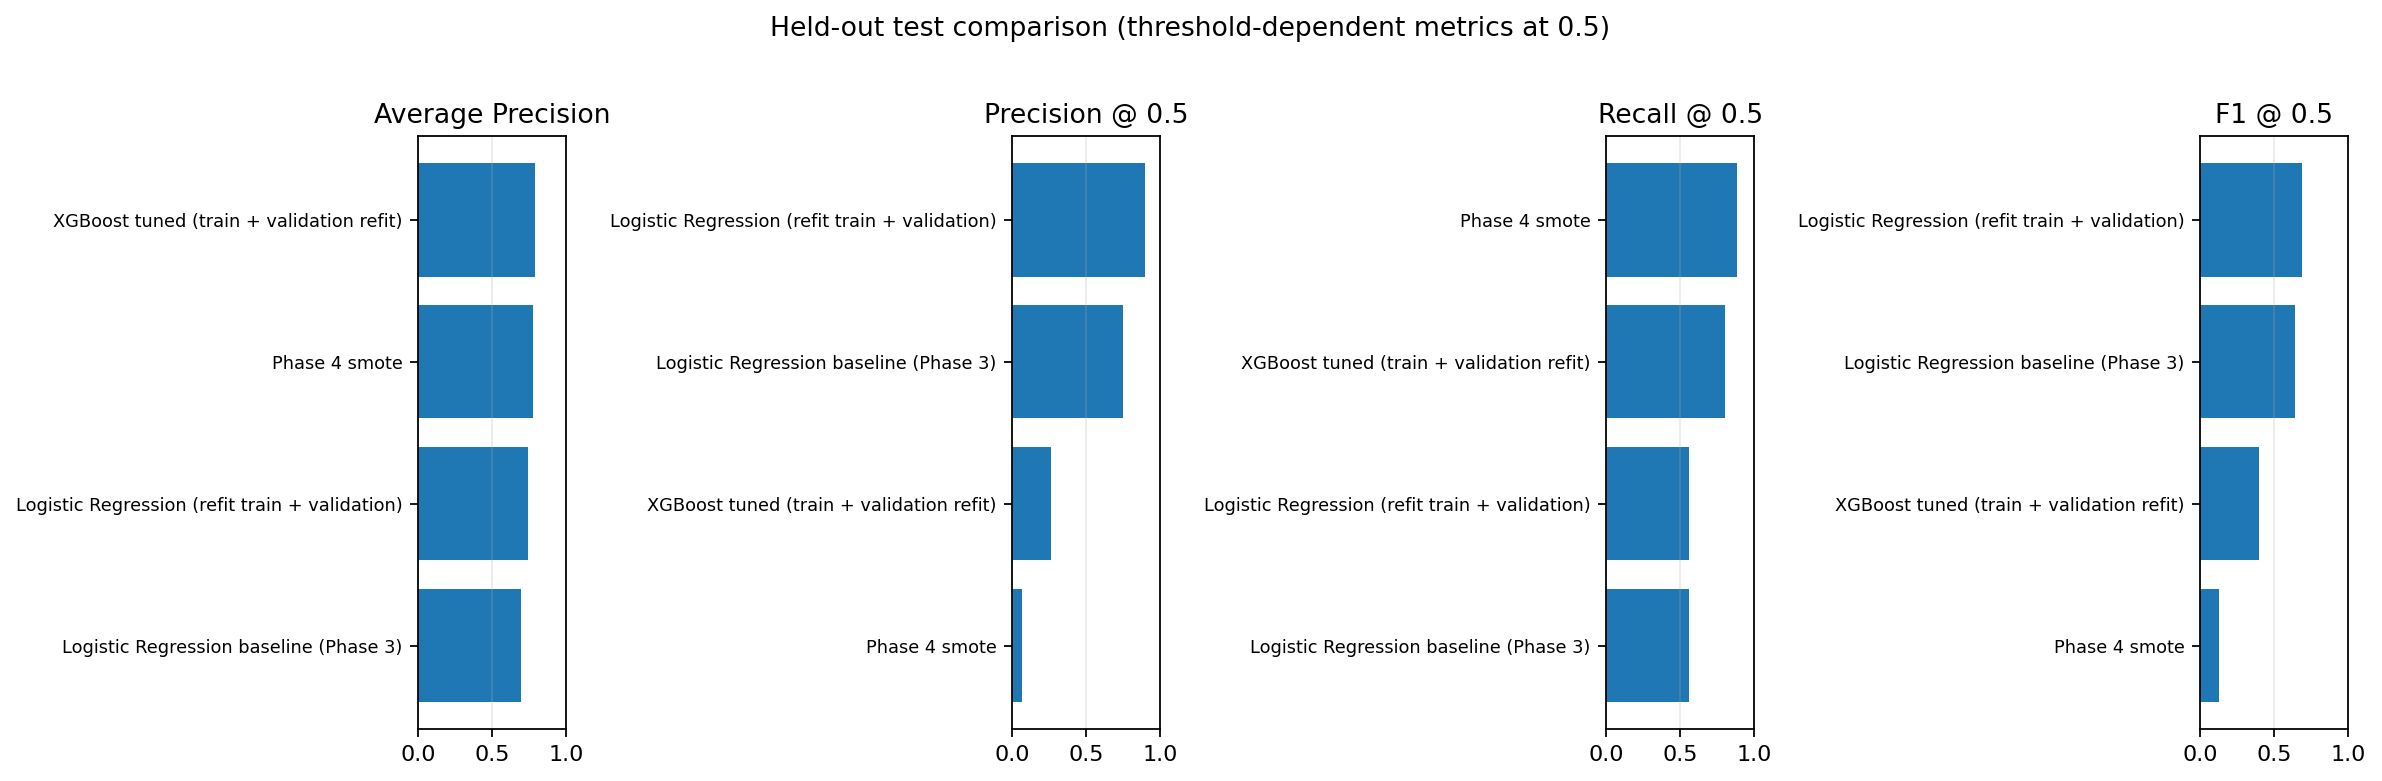

feature_importance.png


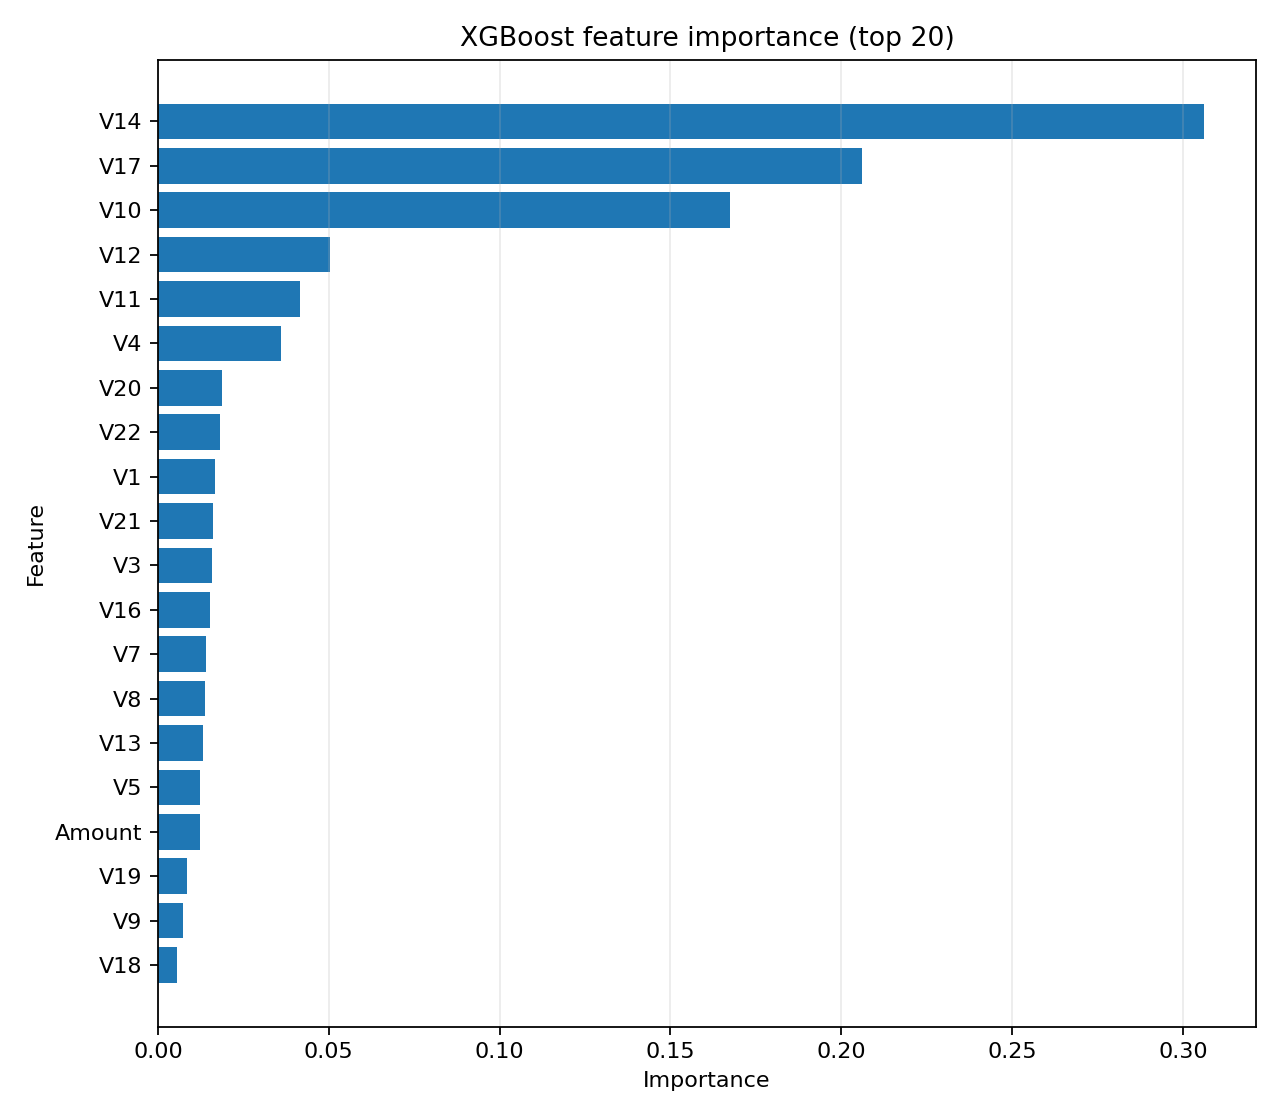

precision_recall_curve_validation.png


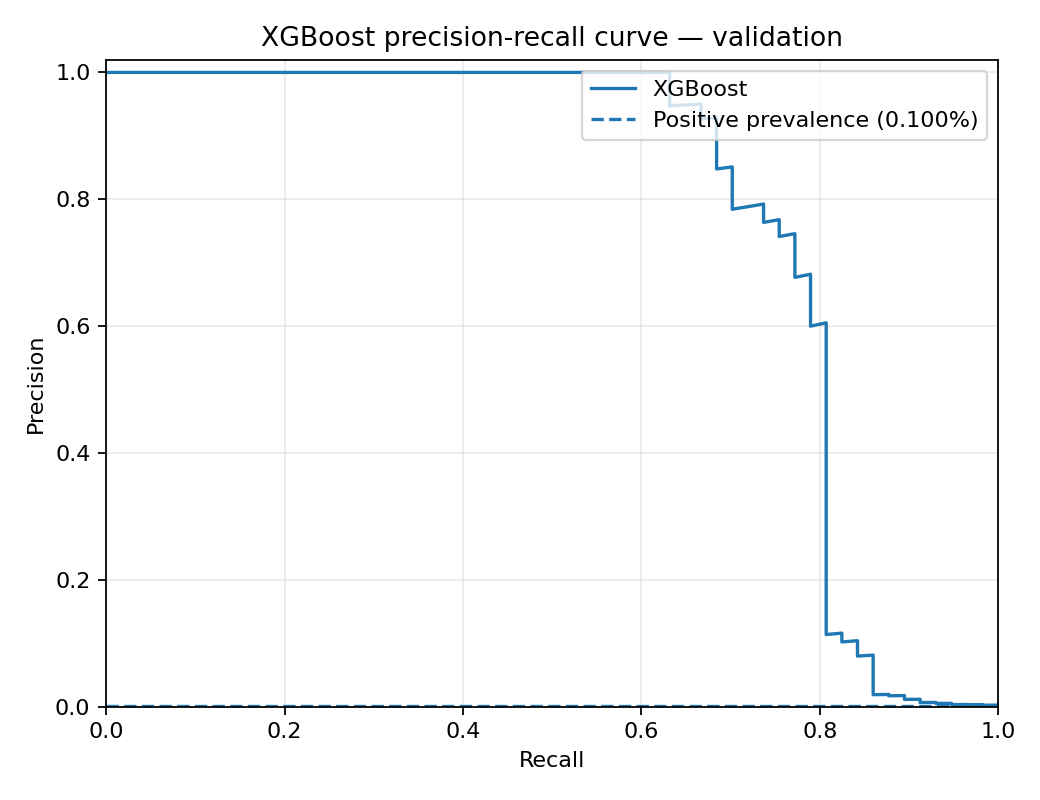

confusion_matrix_test.png


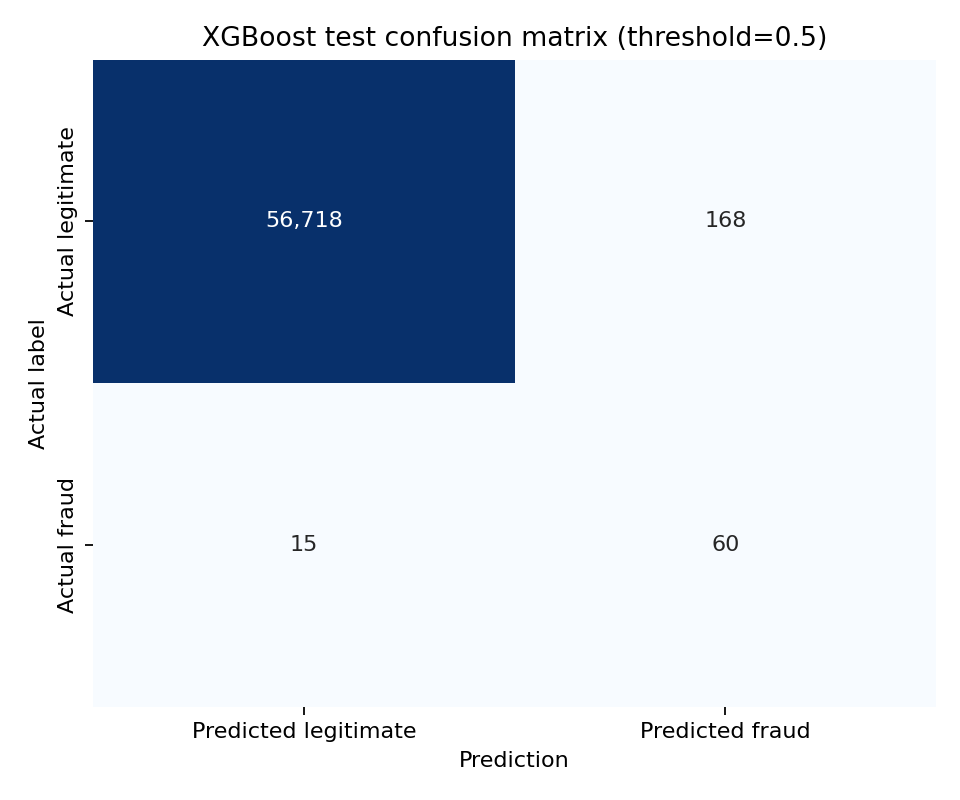

In [4]:
from IPython.display import Image, display
for filename in [
    "test_model_comparison.png",
    "feature_importance.png",
    "precision_recall_curve_validation.png",
    "confusion_matrix_test.png",
]:
    path = ROOT / "reports" / "xgboost" / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))

## 8. Check saved model formats

The joblib file stores the scikit-learn-compatible XGBoost estimator; the JSON file is the native XGBoost model format. Keep the XGBoost version recorded in the report when reloading serialized artifacts.

In [5]:
import joblib
from xgboost import XGBClassifier
from src.data.splitting import chronological_train_validation_test_split

dataset_path = ROOT / "data" / "raw" / "creditcard.csv"
joblib_path = ROOT / "models" / "xgboost_best.joblib"
json_path = ROOT / "models" / "xgboost_best.json"
if dataset_path.exists() and joblib_path.exists() and json_path.exists():
    data = pd.read_csv(dataset_path)
    split = chronological_train_validation_test_split(data)
    features = [column for column in data.columns if column != "Class"]
    X_test = split.test[features].reset_index(drop=True)
    sklearn_model = joblib.load(joblib_path)
    native_model = XGBClassifier()
    native_model.load_model(str(json_path))
    sklearn_scores = sklearn_model.predict_proba(X_test)[:, 1]
    native_scores = native_model.predict_proba(X_test)[:, 1]
    print("Prediction scores match:", bool((abs(sklearn_scores - native_scores) < 1e-6).all()))
else:
    print("Model reload check skipped: dataset or model artifacts not found.")

Prediction scores match: True


## 9. Reproduce from PowerShell

```powershell
pip install -r requirements.txt
python -m src.models.xgboost_model
python -m pytest -q
```

To broaden the search after the default run completes, use `python -m src.models.xgboost_model --n-iter 10 --n-jobs 2`. More candidates improve coverage of the search space but increase runtime. Phase 6 will use the validation partition to choose a decision threshold against a defined objective or cost function; the test threshold must remain untouched.